In [37]:
import json
from pathlib import Path

candidates = [
    Path("data/raw/MACCROBAT2020-V2.json"),
    Path("../../data/raw/MACCROBAT2020-V2.json"),
]

data_path = next((p.resolve() for p in candidates if p.exists()), None)

if data_path is None:
    raise FileNotFoundError("MACCROBAT dataset file not found.")

with data_path.open("r", encoding="utf-8") as file:
    dataset = json.load(file)

print("Dataset loaded successfully!")
print("Dataset path:", data_path)
print("Total records:", len(dataset["data"]))

Dataset loaded successfully!
Dataset path: /Users/muzaffar/Desktop/healthcare-form-entity-extractor/data/raw/MACCROBAT2020-V2.json
Total records: 200


In [38]:
print("Top-level keys:")
print(dataset.keys())

print("\nFirst record keys:")
print(dataset["data"][0].keys())

print("\nFirst record text:")
print(dataset["data"][0]["full_text"][:1000])

Top-level keys:
dict_keys(['data', 'verson', 'all_ner_labels', 'label_2_index', 'index_2_label'])

First record keys:
dict_keys(['full_text', 'ner_info', 'tokens', 'ner_labels'])

First record text:
CASE: A 28-year-old previously healthy man presented with a 6-week history of palpitations.
The symptoms occurred during rest, 2–3 times per week, lasted up to 30 minutes at a time and were associated with dyspnea.
Except for a grade 2/6 holosystolic tricuspid regurgitation murmur (best heard at the left sternal border with inspiratory accentuation), physical examination yielded unremarkable findings.
An electrocardiogram (ECG) revealed normal sinus rhythm and a Wolff– Parkinson– White pre-excitation pattern (Fig.1: Top), produced by a right-sided accessory pathway.
Transthoracic echocardiography demonstrated the presence of Ebstein's anomaly of the tricuspid valve, with apical displacement of the valve and formation of an “atrialized” right ventricle (a functional unit between the right at

In [39]:
record = dataset["data"][0]

print("Tokens (first 30):")
print(record["tokens"][:30])

print("\nNER labels (first 30):")
print(record["ner_labels"][:30])

print("\nEntity information sample:")
print(record["ner_info"][:5])

Tokens (first 30):
['CASE: A ', '28-year-old', ' ', 'previously healthy', ' ', 'man', ' ', 'presented', ' with a ', '6-week', ' history of ', 'palpitations', '.\nThe ', 'symptoms', ' occurred during ', 'rest', ', ', '2–3 times per week', ', lasted ', 'up to 30 minutes at a time', ' and were associated with ', 'dyspnea', '.\nExcept for a ', 'grade 2/6', ' ', 'holosystolic', ' ', 'tricuspid', ' ', 'regurgitation murmur']

NER labels (first 30):
[0, 5, 0, 39, 0, 65, 0, 13, 0, 32, 0, 69, 0, 18, 0, 13, 0, 35, 0, 22, 0, 69, 0, 42, 0, 22, 0, 12, 0, 69]

Entity information sample:
[{'text': '28-year-old', 'label': 'AGE', 'start': 8, 'end': 19}, {'text': 'previously healthy', 'label': 'HISTORY', 'start': 20, 'end': 38}, {'text': 'man', 'label': 'SEX', 'start': 39, 'end': 42}, {'text': 'presented', 'label': 'CLINICAL_EVENT', 'start': 43, 'end': 52}, {'text': '6-week', 'label': 'DURATION', 'start': 60, 'end': 66}]


In [40]:
print("Label mapping sample:")

for label_id, label_name in list(dataset["index_2_label"].items())[:15]:
    print(f"{label_id} -> {label_name}")

Label mapping sample:
0 -> O
1 -> B-ACTIVITY
2 -> I-ACTIVITY
3 -> I-ADMINISTRATION
4 -> B-ADMINISTRATION
5 -> B-AGE
6 -> I-AGE
7 -> I-AREA
8 -> B-AREA
9 -> B-BIOLOGICAL_ATTRIBUTE
10 -> I-BIOLOGICAL_ATTRIBUTE
11 -> I-BIOLOGICAL_STRUCTURE
12 -> B-BIOLOGICAL_STRUCTURE
13 -> B-CLINICAL_EVENT
14 -> I-CLINICAL_EVENT


In [41]:
label_mapping = dataset["index_2_label"]

target_labels = ["DATE", "MEDICATION", "DISEASE_DISORDER"]

for target in target_labels:
    print(f"\n{target}:")

    for label_id, label_name in label_mapping.items():
        if label_name in [f"B-{target}", f"I-{target}"]:
            print(f"  {label_id} -> {label_name}")


DATE:
  19 -> B-DATE
  20 -> I-DATE

MEDICATION:
  45 -> I-MEDICATION
  46 -> B-MEDICATION

DISEASE_DISORDER:
  25 -> I-DISEASE_DISORDER
  26 -> B-DISEASE_DISORDER


In [42]:
from collections import Counter

label_mapping = dataset["index_2_label"]
entity_counts = Counter()

for record in dataset["data"]:
    for label_id in record["ner_labels"]:
        label_name = label_mapping[str(label_id)]

        if label_name.startswith("B-"):
            entity_counts[label_name[2:]] += 1

print("Target entity counts (B-labels):")

for label in ["DATE", "MEDICATION", "DISEASE_DISORDER"]:
    print(f"{label}: {entity_counts[label]}")
    

Target entity counts (B-labels):
DATE: 725
MEDICATION: 1072
DISEASE_DISORDER: 1309


In [43]:
total_records = len(dataset["data"])
mismatches = []

for i, record in enumerate(dataset["data"]):
    tokens = record["tokens"]
    labels = record["ner_labels"]

    if len(tokens) != len(labels):
        mismatches.append({
            "record_index": i,
            "tokens_count": len(tokens),
            "labels_count": len(labels)
        })

print("Total records:", total_records)
print("Records with mismatched lengths:", len(mismatches))

if mismatches:
    print("\nFirst 5 mismatches:")
    print(mismatches[:5])
else:
    print("All records have matching token and label lengths!")
    

Total records: 200
Records with mismatched lengths: 0
All records have matching token and label lengths!


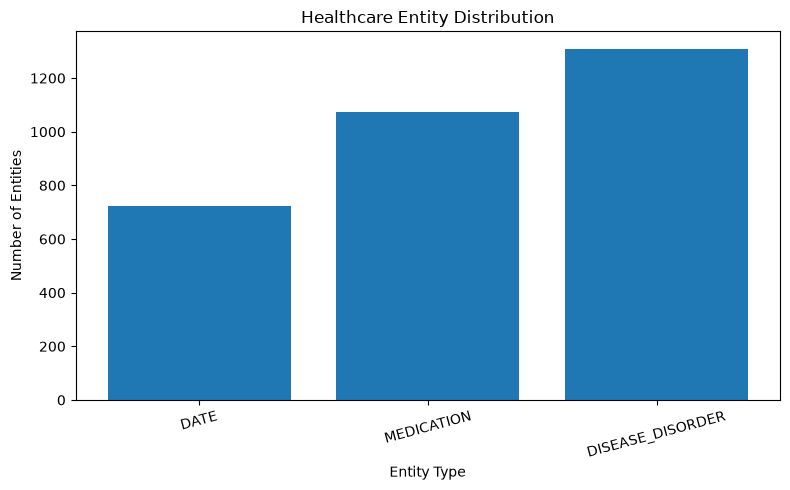

In [44]:
import matplotlib.pyplot as plt

labels = ["DATE", "MEDICATION", "DISEASE_DISORDER"]
counts = [725, 1072, 1309]

plt.figure(figsize=(8, 5))
plt.bar(labels, counts)
plt.title("Healthcare Entity Distribution")
plt.xlabel("Entity Type")
plt.ylabel("Number of Entities")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [45]:
from collections import Counter

label_mapping = dataset["index_2_label"]
entity_counts = Counter()

for record in dataset["data"]:
    for label_id in record["ner_labels"]:
        label_name = label_mapping[str(label_id)]

        if label_name.startswith("B-"):
            entity_name = label_name[2:]
            entity_counts[entity_name] += 1

print("Total unique entity types:", len(entity_counts))
print("\nTop 15 entity types:")

for entity, count in entity_counts.most_common(15):
    print(f"{entity}: {count}")

Total unique entity types: 41

Top 15 entity types:
DIAGNOSTIC_PROCEDURE: 4574
SIGN_SYMPTOM: 3347
BIOLOGICAL_STRUCTURE: 2928
DETAILED_DESCRIPTION: 2892
LAB_VALUE: 2837
DISEASE_DISORDER: 1309
MEDICATION: 1072
THERAPEUTIC_PROCEDURE: 1026
DATE: 725
CLINICAL_EVENT: 625
SEVERITY: 374
DOSAGE: 359
NONBIOLOGICAL_LOCATION: 355
COREFERENCE: 312
HISTORY: 281


In [46]:
TARGET_LABELS = {
    "DATE",
    "MEDICATION",
    "DISEASE_DISORDER",
}

LABEL_MAP = {
    "DATE": "DATE",
    "MEDICATION": "MEDICATION",
    "DISEASE_DISORDER": "CONDITION",
}

print("Source labels:", TARGET_LABELS)
print("Project label mapping:")

for source, target in LABEL_MAP.items():
    print(f"{source} -> {target}")

Source labels: {'DISEASE_DISORDER', 'MEDICATION', 'DATE'}
Project label mapping:
DATE -> DATE
MEDICATION -> MEDICATION
DISEASE_DISORDER -> CONDITION


In [47]:
def convert_label(label_name):
    if label_name == "O":
        return "O"

    prefix, entity = label_name.split("-", 1)

    if entity not in LABEL_MAP:
        return "O"

    return f"{prefix}-{LABEL_MAP[entity]}"


test_labels = [
    "O",
    "B-DATE",
    "I-DATE",
    "B-MEDICATION",
    "I-MEDICATION",
    "B-DISEASE_DISORDER",
    "I-DISEASE_DISORDER",
    "B-AGE",
    "I-AGE",
]

for label in test_labels:
    print(f"{label} -> {convert_label(label)}")

O -> O
B-DATE -> B-DATE
I-DATE -> I-DATE
B-MEDICATION -> B-MEDICATION
I-MEDICATION -> I-MEDICATION
B-DISEASE_DISORDER -> B-CONDITION
I-DISEASE_DISORDER -> I-CONDITION
B-AGE -> O
I-AGE -> O


In [48]:
converted_records = []

label_mapping = dataset["index_2_label"]

for record in dataset["data"]:
    converted_labels = []

    for label_id in record["ner_labels"]:
        original_label = label_mapping[str(label_id)]
        new_label = convert_label(original_label)
        converted_labels.append(new_label)

    converted_records.append({
        "tokens": record["tokens"],
        "labels": converted_labels
    })

print("Total converted records:", len(converted_records))
print("\nFirst record tokens:", len(converted_records[0]["tokens"]))
print("First record labels:", len(converted_records[0]["labels"]))

print("\nFirst 30 converted labels:")
print(converted_records[0]["labels"][:30])

Total converted records: 200

First record tokens: 135
First record labels: 135

First 30 converted labels:
['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


In [49]:
from collections import Counter

converted_counts = Counter()

for record in converted_records:
    for label in record["labels"]:
        if label.startswith("B-"):
            converted_counts[label[2:]] += 1

print("Converted target entity counts:")

for entity in ["DATE", "MEDICATION", "CONDITION"]:
    print(f"{entity}: {converted_counts[entity]}")

Converted target entity counts:
DATE: 725
MEDICATION: 1072
CONDITION: 1309


In [50]:
all_labels = set()

for record in converted_records:
    all_labels.update(record["labels"])

print("Unique converted labels:")
for label in sorted(all_labels):
    print(label)

print("\nTotal unique labels:", len(all_labels))

Unique converted labels:
B-CONDITION
B-DATE
B-MEDICATION
O

Total unique labels: 4


In [51]:
from collections import Counter

original_i_labels = Counter()

label_mapping = dataset["index_2_label"]

for record in dataset["data"]:
    for label_id in record["ner_labels"]:
        label_name = label_mapping[str(label_id)]

        if label_name.startswith("I-"):
            original_i_labels[label_name] += 1

print("Original I-labels for target entities:")

for label in [
    "I-DATE",
    "I-MEDICATION",
    "I-DISEASE_DISORDER"
]:
    print(f"{label}: {original_i_labels[label]}")

Original I-labels for target entities:
I-DATE: 0
I-MEDICATION: 0
I-DISEASE_DISORDER: 0


In [52]:
label_mapping = dataset["index_2_label"]

print("Mapping type:", type(label_mapping).__name__)

print("\nTarget I-label IDs:")
for label_id, label_name in label_mapping.items():
    if label_name in [
        "I-DATE",
        "I-MEDICATION",
        "I-DISEASE_DISORDER"
    ]:
        print(label_id, "->", label_name)

Mapping type: dict

Target I-label IDs:
20 -> I-DATE
25 -> I-DISEASE_DISORDER
45 -> I-MEDICATION


In [53]:
from collections import Counter

i_label_ids = {"20", "25", "45"}
found_ids = Counter()

for record in dataset["data"]:
    for label_id in record["ner_labels"]:
        if str(label_id) in i_label_ids:
            found_ids[str(label_id)] += 1

print("I-label occurrences in actual records:")

for label_id in sorted(i_label_ids, key=int):
    label_name = label_mapping[label_id]
    print(f"{label_name} (ID {label_id}): {found_ids[label_id]}")

I-label occurrences in actual records:
I-DATE (ID 20): 0
I-DISEASE_DISORDER (ID 25): 0
I-MEDICATION (ID 45): 0


In [54]:
record = dataset["data"][0]

print("First 10 entity annotations:\n")

for entity in record["ner_info"][:10]:
    print(entity)

print("\nFirst 40 token-label pairs:\n")

for token, label_id in zip(
    record["tokens"][:40],
    record["ner_labels"][:40]
):
    print(repr(token), "->", label_mapping[str(label_id)])

First 10 entity annotations:

{'text': '28-year-old', 'label': 'AGE', 'start': 8, 'end': 19}
{'text': 'previously healthy', 'label': 'HISTORY', 'start': 20, 'end': 38}
{'text': 'man', 'label': 'SEX', 'start': 39, 'end': 42}
{'text': 'presented', 'label': 'CLINICAL_EVENT', 'start': 43, 'end': 52}
{'text': '6-week', 'label': 'DURATION', 'start': 60, 'end': 66}
{'text': 'palpitations', 'label': 'SIGN_SYMPTOM', 'start': 78, 'end': 90}
{'text': 'symptoms', 'label': 'COREFERENCE', 'start': 96, 'end': 104}
{'text': 'rest', 'label': 'CLINICAL_EVENT', 'start': 121, 'end': 125}
{'text': '2–3 times per week', 'label': 'FREQUENCY', 'start': 127, 'end': 145}
{'text': 'up to 30 minutes at a time', 'label': 'DETAILED_DESCRIPTION', 'start': 154, 'end': 180}

First 40 token-label pairs:

'CASE: A ' -> O
'28-year-old' -> B-AGE
' ' -> O
'previously healthy' -> B-HISTORY
' ' -> O
'man' -> B-SEX
' ' -> O
'presented' -> B-CLINICAL_EVENT
' with a ' -> O
'6-week' -> B-DURATION
' history of ' -> O
'palpitation

In [55]:
for record_index, record in enumerate(dataset["data"]):
    target_entities = [
        entity for entity in record["ner_info"]
        if entity["label"] in {
            "DATE",
            "MEDICATION",
            "DISEASE_DISORDER",
        }
    ]

    if target_entities:
        print("Record index:", record_index)
        print("Full text preview:")
        print(record["full_text"][:500])

        print("\nTarget entity annotations:")
        for entity in target_entities[:10]:
            print(entity)

        break

Record index: 0
Full text preview:
CASE: A 28-year-old previously healthy man presented with a 6-week history of palpitations.
The symptoms occurred during rest, 2–3 times per week, lasted up to 30 minutes at a time and were associated with dyspnea.
Except for a grade 2/6 holosystolic tricuspid regurgitation murmur (best heard at the left sternal border with inspiratory accentuation), physical examination yielded unremarkable findings.
An electrocardiogram (ECG) revealed normal sinus rhythm and a Wolff– Parkinson– White pre-excit

Target entity annotations:
{'text': 'accessory pathway', 'label': 'DISEASE_DISORDER', 'start': 554, 'end': 571}
{'text': "Ebstein's anomaly", 'label': 'DISEASE_DISORDER', 'start': 633, 'end': 650}
{'text': 'atrialized', 'label': 'DISEASE_DISORDER', 'start': 734, 'end': 744}
{'text': 'patent foramen ovale', 'label': 'DISEASE_DISORDER', 'start': 1052, 'end': 1072}
{'text': 'abnormal impulse conduction', 'label': 'DISEASE_DISORDER', 'start': 1528, 'end': 1555}
{

In [56]:
record = dataset["data"][0]
text = record["full_text"]

for entity in record["ner_info"]:
    if entity["label"] in {
        "DATE",
        "MEDICATION",
        "DISEASE_DISORDER",
    }:
        extracted_text = text[entity["start"]:entity["end"]]

        print("Original:", repr(entity["text"]))
        print("From positions:", repr(extracted_text))
        print("Match:", extracted_text == entity["text"])
        print()

Original: 'accessory pathway'
From positions: 'accessory pathway'
Match: True

Original: "Ebstein's anomaly"
From positions: "Ebstein's anomaly"
Match: True

Original: 'atrialized'
From positions: 'atrialized'
Match: True

Original: 'patent foramen ovale'
From positions: 'patent foramen ovale'
Match: True

Original: 'abnormal impulse conduction'
From positions: 'abnormal impulse conduction'
Match: True

Original: 'atrialized'
From positions: 'atrialized'
Match: True

Original: '6 months after'
From positions: '6 months after'
Match: True



In [57]:
def create_bio_labels(record):
    text = record["full_text"]
    tokens = record["tokens"]
    ner_info = record["ner_info"]

    labels = ["O"] * len(tokens)

    # Track each token's character position in the full text.
    cursor = 0
    token_spans = []

    for token in tokens:
        start = text.find(token, cursor)

        if start == -1:
            raise ValueError(f"Token not found: {token!r}")

        end = start + len(token)
        token_spans.append((start, end))
        cursor = end

    # Apply target entity labels using character offsets.
    for entity in ner_info:
        source_label = entity["label"]

        if source_label not in LABEL_MAP:
            continue

        entity_start = entity["start"]
        entity_end = entity["end"]
        target_label = LABEL_MAP[source_label]

        matched_tokens = [
            i
            for i, (token_start, token_end) in enumerate(token_spans)
            if token_start < entity_end and token_end > entity_start
        ]

        for position, token_index in enumerate(matched_tokens):
            prefix = "B-" if position == 0 else "I-"
            labels[token_index] = prefix + target_label

    return labels


test_record = dataset["data"][0]
test_labels = create_bio_labels(test_record)

print("Tokens:", len(test_record["tokens"]))
print("Generated labels:", len(test_labels))
print("\nTarget labels found:")

for token, label in zip(test_record["tokens"], test_labels):
    if label != "O":
        print(repr(token), "->", label)

Tokens: 135
Generated labels: 135

Target labels found:
'accessory pathway' -> B-CONDITION
"Ebstein's anomaly" -> B-CONDITION
'atrialized' -> B-CONDITION
'patent foramen ovale' -> B-CONDITION
'abnormal impulse conduction' -> B-CONDITION
'atrialized' -> B-CONDITION
'6 months after' -> B-DATE


In [58]:
record = dataset["data"][0]

for entity in record["ner_info"]:
    if entity["label"] == "DISEASE_DISORDER":
        start = entity["start"]
        end = entity["end"]

        print("Entity:", entity["text"])
        print("Character span:", start, end)

        for i, token in enumerate(record["tokens"]):
            if token and token in entity["text"]:
                print("Token:", repr(token))

        print("-" * 40)

Entity: accessory pathway
Character span: 554 571
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: 'accessory pathway'
Token: ' '
Token: ' '
Token: ' '
Token: 'accessory pathway'
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
----------------------------------------
Entity: Ebstein's anomaly
Character span: 633 650
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: "Ebstein's anomaly"
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
----------------------------------------
Entity: atrialized
Character span: 734 744
Token: 'atrialized'
Token: 'atrialized'
----------------------------------------
Entity: patent foramen ovale
Character span: 1052 1072
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: 'patent foramen ovale'
Token: ' '
Token: ' '
Token: ' '
Token: ' '
Token: ' '


In [59]:
record = dataset["data"][0]
text = record["full_text"]

cursor = 0
token_spans = []

for token in record["tokens"]:
    start = text.find(token, cursor)

    if start == -1:
        print("Alignment failed for token:", repr(token))
        break

    end = start + len(token)
    token_spans.append((start, end))
    cursor = end

print("Total tokens:", len(record["tokens"]))
print("Total token spans:", len(token_spans))

entity = next(
    e for e in record["ner_info"]
    if e["text"] == "patent foramen ovale"
)

print("\nEntity:", entity["text"])
print("Entity span:", entity["start"], entity["end"])

print("\nOverlapping tokens:")
for i, (start, end) in enumerate(token_spans):
    if start < entity["end"] and end > entity["start"]:
        print(
            repr(record["tokens"][i]),
            (start, end),
            "->",
            repr(text[start:end])
        )

Total tokens: 135
Total token spans: 135

Entity: patent foramen ovale
Entity span: 1052 1072

Overlapping tokens:
'patent foramen ovale' (1052, 1072) -> 'patent foramen ovale'


In [60]:
multi_token_entities = []

for record_index, record in enumerate(dataset["data"]):
    text = record["full_text"]
    cursor = 0
    token_spans = []

    for token in record["tokens"]:
        start = text.find(token, cursor)

        if start == -1:
            raise ValueError(
                f"Token alignment failed in record {record_index}: {token!r}"
            )

        end = start + len(token)
        token_spans.append((start, end))
        cursor = end

    for entity in record["ner_info"]:
        if entity["label"] not in LABEL_MAP:
            continue

        overlapping = [
            i for i, (start, end) in enumerate(token_spans)
            if start < entity["end"] and end > entity["start"]
        ]

        if len(overlapping) > 1:
            multi_token_entities.append({
                "record_index": record_index,
                "text": entity["text"],
                "label": entity["label"],
                "token_count": len(overlapping),
            })

print("Target entities spanning multiple tokens:", len(multi_token_entities))
print("\nFirst 10 examples:")

for entity in multi_token_entities[:10]:
    print(entity)

Target entities spanning multiple tokens: 0

First 10 examples:


In [61]:
final_records = []

for record in dataset["data"]:
    labels = create_bio_labels(record)

    final_records.append({
        "tokens": record["tokens"],
        "labels": labels
    })

print("Total records:", len(final_records))
print("First record token count:", len(final_records[0]["tokens"]))
print("First record label count:", len(final_records[0]["labels"]))

print("\nFinal label distribution:")

from collections import Counter

final_counts = Counter(
    label
    for record in final_records
    for label in record["labels"]
)

for label, count in sorted(final_counts.items()):
    print(f"{label}: {count}")

Total records: 200
First record token count: 135
First record label count: 135

Final label distribution:
B-CONDITION: 1309
B-DATE: 725
B-MEDICATION: 1072
O: 46684


In [62]:
alignment_errors = []

for i, record in enumerate(dataset["data"]):
    reconstructed_text = "".join(record["tokens"])

    if reconstructed_text != record["full_text"]:
        alignment_errors.append(i)

print("Records with token reconstruction errors:", len(alignment_errors))


Records with token reconstruction errors: 0


In [63]:
import re

sample_text = dataset["data"][0]["full_text"]

word_tokens = [
    match.group()
    for match in re.finditer(r"\w+(?:[-'][\w]+)*|[^\w\s]", sample_text)
]

print("Original text preview:")
print(sample_text[:200])

print("\nWord-level tokens:")
print(word_tokens[:40])

print("\nTotal word-level tokens:", len(word_tokens))

Original text preview:
CASE: A 28-year-old previously healthy man presented with a 6-week history of palpitations.
The symptoms occurred during rest, 2–3 times per week, lasted up to 30 minutes at a time and were associated

Word-level tokens:
['CASE', ':', 'A', '28-year-old', 'previously', 'healthy', 'man', 'presented', 'with', 'a', '6-week', 'history', 'of', 'palpitations', '.', 'The', 'symptoms', 'occurred', 'during', 'rest', ',', '2', '–', '3', 'times', 'per', 'week', ',', 'lasted', 'up', 'to', '30', 'minutes', 'at', 'a', 'time', 'and', 'were', 'associated', 'with']

Total word-level tokens: 310


In [64]:
import re

def tokenize_with_offsets(text):
    return [
        (match.group(), match.start(), match.end())
        for match in re.finditer(
            r"\w+(?:[-'][\w]+)*|[^\w\s]", text
        )
    ]

record = dataset["data"][0]
tokens_with_offsets = tokenize_with_offsets(record["full_text"])

for entity in record["ner_info"]:
    if entity["label"] in LABEL_MAP:
        overlapping = [
            token
            for token, start, end in tokens_with_offsets
            if start < entity["end"] and end > entity["start"]
        ]

        print(f"{entity['label']}: {entity['text']}")
        print("Tokens:", overlapping)
        print()

DISEASE_DISORDER: accessory pathway
Tokens: ['accessory', 'pathway']

DISEASE_DISORDER: Ebstein's anomaly
Tokens: ["Ebstein's", 'anomaly']

DISEASE_DISORDER: atrialized
Tokens: ['atrialized']

DISEASE_DISORDER: patent foramen ovale
Tokens: ['patent', 'foramen', 'ovale']

DISEASE_DISORDER: abnormal impulse conduction
Tokens: ['abnormal', 'impulse', 'conduction']

DISEASE_DISORDER: atrialized
Tokens: ['atrialized']

DATE: 6 months after
Tokens: ['6', 'months', 'after']



In [67]:
def create_word_level_records(record):
    text = record["full_text"]
    tokens_with_offsets = tokenize_with_offsets(text)

    labels = ["O"] * len(tokens_with_offsets)

    for entity in record["ner_info"]:
        source_label = entity["label"]

        if source_label not in LABEL_MAP:
            continue

        entity_start = entity["start"]
        entity_end = entity["end"]
        target_label = LABEL_MAP[source_label]

        matched_indices = [
            i
            for i, (_, start, end) in enumerate(tokens_with_offsets)
            if start < entity_end and end > entity_start
        ]

        for position, token_index in enumerate(matched_indices):
            prefix = "B-" if position == 0 else "I-"
            labels[token_index] = prefix + target_label

    return {
        "tokens": [token for token, _, _ in tokens_with_offsets],
        "labels": labels
    }


word_level_records = [
    create_word_level_records(record)
    for record in dataset["data"]
]

print("Total records:", len(word_level_records))
print("First record token count:", len(word_level_records[0]["tokens"]))
print("First record label count:", len(word_level_records[0]["labels"]))

Total records: 200
First record token count: 310
First record label count: 310


In [68]:
record = dataset["data"][0]

for entity in record["ner_info"]:
    if entity["label"] not in LABEL_MAP:
        continue

    start = entity["start"]
    end = entity["end"]

    print(f"\nEntity: {entity['text']}")

    for token, label, (_, token_start, token_end) in zip(
        word_level_records[0]["tokens"],
        word_level_records[0]["labels"],
        tokenize_with_offsets(record["full_text"])
    ):
        if token_start < end and token_end > start:
            print(f"  {token:20} -> {label}")


Entity: accessory pathway
  accessory            -> B-CONDITION
  pathway              -> I-CONDITION

Entity: Ebstein's anomaly
  Ebstein's            -> B-CONDITION
  anomaly              -> I-CONDITION

Entity: atrialized
  atrialized           -> B-CONDITION

Entity: patent foramen ovale
  patent               -> B-CONDITION
  foramen              -> I-CONDITION
  ovale                -> I-CONDITION

Entity: abnormal impulse conduction
  abnormal             -> B-CONDITION
  impulse              -> I-CONDITION
  conduction           -> I-CONDITION

Entity: atrialized
  atrialized           -> B-CONDITION

Entity: 6 months after
  6                    -> B-DATE
  months               -> I-DATE
  after                -> I-DATE


In [69]:
from collections import Counter

label_counts = Counter(
    label
    for record in word_level_records
    for label in record["labels"]
)

print("Total records:", len(word_level_records))
print("Total word-level tokens:", sum(label_counts.values()))

print("\nLabel distribution:")
for label, count in sorted(label_counts.items()):
    print(f"{label}: {count}")

print("\nToken-label length mismatches:")
mismatches = sum(
    len(record["tokens"]) != len(record["labels"])
    for record in word_level_records
)
print(mismatches)

Total records: 200
Total word-level tokens: 103567

Label distribution:
B-CONDITION: 1309
B-DATE: 725
B-MEDICATION: 1072
I-CONDITION: 818
I-DATE: 1388
I-MEDICATION: 318
O: 97937

Token-label length mismatches:
0


In [70]:
conflicts = []

for record_index, record in enumerate(dataset["data"]):
    tokens_with_offsets = tokenize_with_offsets(record["full_text"])

    for i, first in enumerate(record["ner_info"]):
        if first["label"] not in LABEL_MAP:
            continue

        for second in record["ner_info"][i + 1:]:
            if second["label"] not in LABEL_MAP:
                continue

            overlaps = (
                first["start"] < second["end"]
                and second["start"] < first["end"]
            )

            if overlaps:
                conflicts.append({
                    "record": record_index,
                    "first_entity": first["text"],
                    "second_entity": second["text"]
                })

print("Target entity overlap conflicts:", len(conflicts))
print("First 10 conflicts:")

for conflict in conflicts[:10]:
    print(conflict)

Target entity overlap conflicts: 0
First 10 conflicts:


In [71]:
import json
from pathlib import Path

output_dir = Path("../../data/processed")

# If the notebook is running from the repository root instead,
# use Path("data/processed") instead.
if not Path("../../data/raw/MACCROBAT2020-V2.json").exists():
    output_dir = Path("data/processed")

output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "healthcare_ner_processed.json"

with output_path.open("w", encoding="utf-8") as file:
    json.dump(word_level_records, file, ensure_ascii=False, indent=2)

print("Processed dataset saved!")
print("File path:", output_path.resolve())
print("Total records:", len(word_level_records))

Processed dataset saved!
File path: /Users/muzaffar/Desktop/healthcare-form-entity-extractor/data/processed/healthcare_ner_processed.json
Total records: 200


In [72]:
import json
from pathlib import Path

output_path = Path("../../data/processed/healthcare_ner_processed.json")

if not output_path.exists():
    output_path = Path("data/processed/healthcare_ner_processed.json")

with output_path.open("r", encoding="utf-8") as file:
    saved_records = json.load(file)

print("File loaded successfully:", output_path.resolve())
print("Total records:", len(saved_records))

mismatches = sum(
    len(record["tokens"]) != len(record["labels"])
    for record in saved_records
)

print("Token-label mismatches:", mismatches)
print("First 10 tokens:", saved_records[0]["tokens"][:10])
print("First 10 labels:", saved_records[0]["labels"][:10])

File loaded successfully: /Users/muzaffar/Desktop/healthcare-form-entity-extractor/data/processed/healthcare_ner_processed.json
Total records: 200
Token-label mismatches: 0
First 10 tokens: ['CASE', ':', 'A', '28-year-old', 'previously', 'healthy', 'man', 'presented', 'with', 'a']
First 10 labels: ['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']
